### BUILD A BASIC CHATBOT WITH LANGGRAPH(GRAPH API)

In [1]:
from typing import Annotated
from typing_extensions import  TypedDict
from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    # message have the type "list". the 'add_messages' function will add the messages to the state.
    # In the annotation defines how this state key should be updated 
    # (in this case it appends messages to the list of messages in the state)
    messages: Annotated[list, add_messages]


 

In [3]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv()

os.environ["ANTHROPIC_API_KEY"] = os.getenv("ANTHROPIC_API_KEY")

llm = init_chat_model("claude-sonnet-4-6")


In [4]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [5]:
graph_builder = StateGraph(State)
## Adding Node
graph_builder.add_node("chatbot", chatbot)

## Adding Edge
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

## Compile the graph
graph = graph_builder.compile()


In [6]:
from IPython.display import display,Image

try:
    display(Image(graph.get_graph_image().draw_mermaid_png()))
except Exception as e:
    pass

In [7]:
response= graph.invoke({"messages": "Hello"})

In [ ]:
response["messages"][-1].content

'Hello! How are you doing? Is there something I can help you with today? 😊'

In [ ]:
for event in graph.stream({"messages":"hil How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi! I'm doing well, thanks for asking! 😊 How are you doing? Is there something I can help you with today?


### Chatbot with Tool

In [10]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("what is langchain?")

{'query': 'what is langchain?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://aws.amazon.com/what-is/langchain',
   'title': 'What is LangChain? - LangChain Explained - AWS',
   'content': 'LangChain is an open source framework for building applications based on large language models (LLMs). LLMs are large deep-learning models pre-trained on large amounts of data that can generate responses to user queries—for example, answering questions or creating images from text-based prompts. LangChain provides tools and abstractions to improve the customization, accuracy, and relevancy of the information the models generate. For example, developers can use LangChain components to build new [...] LangChain provides AI developers with tools to connect language models with external data sources. It is open-source and supported by an active community. Organizations can use LangChain for free and receive support from other developers proficient in the fra

In [11]:
## Custom Tool
def multiply(a: int, b: int) -> int:
    """__Summary__
    Args:
        a (int): first number
        b (int): second number
    Returns:
        int: __description__ output int
    """
    return a * b

In [12]:
tools=[tool, multiply]

In [13]:
llm_with_tools = llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatAnthropic(metadata={'lc_versions': {'langchain-core': '1.6.5', 'langchain': '1.4.2', 'langchain-anthropic': '1.7.4'}}, profile={'name': 'Claude Sonnet 4.6', 'release_date': '2026-02-17', 'last_updated': '2026-03-13', 'open_weights': False, 'max_input_tokens': 1000000, 'max_output_tokens': 128000, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_call_streaming': True, 'reasoning_effort_levels': ['low', 'medium', 'high', 'max'], 'reasoning_effort_default': 'high'}, model='claude-sonnet-4-6', max_tokens=128000, anthropic_api_url='https://api.anthropic.com', anthropic_api_key=SecretStr('**********'), model_kwargs

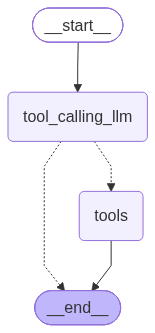

In [17]:
### Create StateGraph with tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
                              # if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
                              # if the latest message (result) from assistant is not a tool call -> tools_condition routes to END 
                              tools_condition)
builder.add_edge("tools", END)

## Compile the graph
graph=builder.compile()

from IPython.display import display,Image
display(Image(graph.get_graph().draw_mermaid_png()))


 

In [21]:
response=graph.invoke({"messages": "what is the recent news?"})

In [22]:
response["messages"][-1].content

'{"query": "recent news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://drydenwire.com/news/morning-headlines-tuesday-oct-20-2026", "title": "Morning Headlines - Tuesday, Oct. 20, 2026 | Recent News | DrydenWire.com", "content": "It seems that almost daily, a big tech company releases a new AI-driven digital assistant. Muse by Meta, Gemini by Google, dots by OpenAI. By the time this article is published, a new one from [insert tech company here] will probably have a press release touting its ability to manage your work and life — to take things off your plate, automate your processes, speed up your tedious tasks. It sounds helpful and, to lower the bar, harmless. [...] Filing for a restraining order used to mean a trip to the courthouse, a stack of paperwork, and a process advocates describe as intimidating for people who were already in crisis.\\n\\nNow, Wisconsin survivors can do it from a phone, a tablet, or any computer with an intern

In [ ]:
response=graph.invoke({"messages": "what is the recent news and 5 by 2 z?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the recent news?
================================== Ai Message ==================================

[{'id': 'toolu_018ZoTLtpEZQMvzCr5tqqZQU', 'caller': {'type': 'direct'}, 'input': {'query': 'recent news today', 'topic': 'news', 'time_range': 'day', 'search_depth': 'basic'}, 'name': 'tavily_search', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  tavily_search (toolu_018ZoTLtpEZQMvzCr5tqqZQU)
 Call ID: toolu_018ZoTLtpEZQMvzCr5tqqZQU
  Args:
    query: recent news today
    topic: news
    time_range: day
    search_depth: basic
================================= Tool Message =================================
Name: tavily_search

{"query": "recent news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://drydenwire.com/news/morning-headlines-tuesday-oct-20-2026", "title": "Morning Headlines - Tuesday, Oct. 20, 2026 | Recent News | DrydenWire.com", "

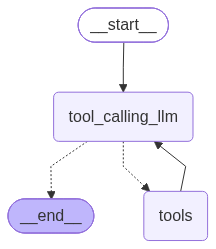

In [26]:
### React Agent Architecture
### Create StateGraph with tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

## Node Defination
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}


builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Adding Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",
                              # if the latest message (result) from assistant is a tool call -> tools_condition routes to tools
                              # if the latest message (result) from assistant is not a tool call -> tools_condition routes to END 
                              tools_condition)
builder.add_edge("tools", "tool_calling_llm")

## Compile the graph
graph=builder.compile()

from IPython.display import display,Image
display(Image(graph.get_graph().draw_mermaid_png()))

In [27]:
response=graph.invoke({"messages": "what is the recent news and then 5 multiply by 2?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the recent news and then 5 multiply by 2?
================================== Ai Message ==================================

[{'text': "I'll handle both requests simultaneously! Let me search for recent news and calculate 5 × 2 at the same time.", 'type': 'text'}, {'id': 'toolu_01AfepPvMzbhdzDRyvZJBHQ3', 'caller': {'type': 'direct'}, 'input': {'query': 'recent news today', 'time_range': 'day', 'topic': 'news'}, 'name': 'tavily_search', 'type': 'tool_use', 'toolset_name': None}, {'id': 'toolu_01L5G74LHzXCsNLzKG1QVphE', 'caller': {'type': 'direct'}, 'input': {'a': 5, 'b': 2}, 'name': 'multiply', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  tavily_search (toolu_01AfepPvMzbhdzDRyvZJBHQ3)
 Call ID: toolu_01AfepPvMzbhdzDRyvZJBHQ3
  Args:
    query: recent news today
    time_range: day
    topic: news
  multiply (toolu_01L5G74LHzXCsNLzKG1QVphE)
 Call ID: toolu_01L5G74LHzXCsNLzKG1QVphE
  Args: